In [33]:
# IMPORT LIBRARIES 

import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler 
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LogisticRegression 
from sklearn.metrics import classification_report,accuracy_score 
from sklearn.preprocessing import StandardScaler 
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import os

import joblib

In [39]:
# ── Create a folder to store all visuals ─────────────────────
os.makedirs('visuals', exist_ok=True)

In [4]:
hd = pd.read_csv('Heart_Disease_Prediction.csv')
hd.head()

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,Presence
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,Absence
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,Presence
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,Absence
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,Absence


In [5]:
hd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      270 non-null    int64  
 1   Sex                      270 non-null    int64  
 2   Chest pain type          270 non-null    int64  
 3   BP                       270 non-null    int64  
 4   Cholesterol              270 non-null    int64  
 5   FBS over 120             270 non-null    int64  
 6   EKG results              270 non-null    int64  
 7   Max HR                   270 non-null    int64  
 8   Exercise angina          270 non-null    int64  
 9   ST depression            270 non-null    float64
 10  Slope of ST              270 non-null    int64  
 11  Number of vessels fluro  270 non-null    int64  
 12  Thallium                 270 non-null    int64  
 13  Heart Disease            270 non-null    object 
dtypes: float64(1), int64(12), 

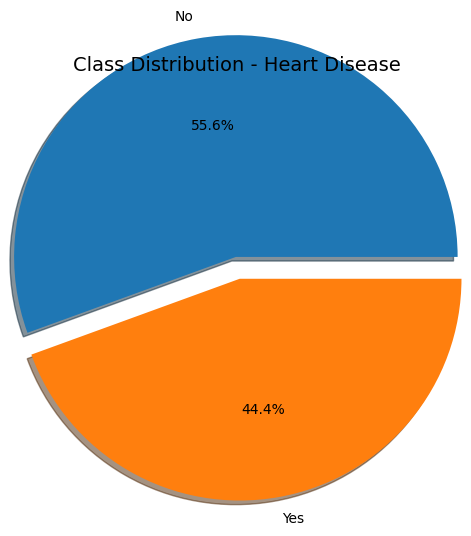

Saved: class_distribution.png


In [40]:
# check for class imbalance

r = hd.groupby('Heart Disease')['Heart Disease'].count()
plt.pie(r, explode=[0.05, 0.1], labels=['No', 'Yes'], radius=1.5, autopct='%1.1f%%',  shadow=True); 

plt.title('Class Distribution - Heart Disease', fontsize=14)
plt.savefig('visuals/class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: class_distribution.png")
# class is fairly good balanced, so we can proceed with the model building without using any sampling techniques.

In [7]:
# label encoding target variable

le = LabelEncoder().fit_transform
hd["Heart Disease Encoded"] = LabelEncoder().fit_transform(hd["Heart Disease"])

In [8]:
# standard scale - age, BP. CHOLESTROL, MAX HR.

In [9]:
hd

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease,Heart Disease Encoded
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,Presence,1
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,Absence,0
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,Presence,1
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,Absence,0
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,Absence,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
265,52,1,3,172,199,1,0,162,0,0.5,1,0,7,Absence,0
266,44,1,2,120,263,0,0,173,0,0.0,1,0,7,Absence,0
267,56,0,2,140,294,0,2,153,0,1.3,2,0,3,Absence,0
268,57,1,4,140,192,0,0,148,0,0.4,2,0,6,Absence,0


In [10]:
cd = columns_to_drop = ["Heart Disease"]
New_hd = hd.drop(columns=cd)

In [11]:
New_hd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      270 non-null    int64  
 1   Sex                      270 non-null    int64  
 2   Chest pain type          270 non-null    int64  
 3   BP                       270 non-null    int64  
 4   Cholesterol              270 non-null    int64  
 5   FBS over 120             270 non-null    int64  
 6   EKG results              270 non-null    int64  
 7   Max HR                   270 non-null    int64  
 8   Exercise angina          270 non-null    int64  
 9   ST depression            270 non-null    float64
 10  Slope of ST              270 non-null    int64  
 11  Number of vessels fluro  270 non-null    int64  
 12  Thallium                 270 non-null    int64  
 13  Heart Disease Encoded    270 non-null    int64  
dtypes: float64(1), int64(13)
m

In [12]:
features = ["BP","Cholesterol","Chest pain type","Sex","FBS over 120","Max HR","Exercise angina","ST depression","Slope of ST","Number of vessels fluro","Thallium"]
output = ["Heart Disease Encoded"]

In [13]:
X = New_hd[features]
y = New_hd[output]

In [14]:
X_train, X_test,y_train, y_test =train_test_split(X,y,test_size = 0.2,random_state = 42, stratify = y)

Checking test data

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ADD THIS RIGHT AFTER
X_test.to_csv('test_set.csv', index=False)
y_test.to_csv('test_labels.csv', index=False)

print("Test set saved!")
print(f"Test set size: {len(X_test)} rows")

Test set saved!
Test set size: 54 rows


In [15]:
#STANDARDIZATION
# Scaler
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [16]:
#DEFINE A MODEL
#Start with Logistic Regression

model_LR = LogisticRegression(max_iter=1000, class_weight = "balanced")
model_LR.fit(X_train,y_train)

c:\Users\akeem\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [17]:
#evaluate
y_pred = model_LR.predict(X_test)

In [18]:
#print accuracy score
print("accuracy_score:")

print(accuracy_score(y_test,y_pred))

accuracy_score:
0.8518518518518519


In [19]:
print("classification report:")

print(classification_report(y_test,y_pred))

classification report:
              precision    recall  f1-score   support

           0       0.92      0.80      0.86        30
           1       0.79      0.92      0.85        24

    accuracy                           0.85        54
   macro avg       0.85      0.86      0.85        54
weighted avg       0.86      0.85      0.85        54



In [20]:
#RandomForestClassifier
model_rfc = RandomForestClassifier(n_estimators=100, class_weight ="balanced", random_state = 42)

model_rfc.fit(X_train,y_train)

c:\Users\akeem\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [21]:
#evaluate
y_pred = model_rfc.predict(X_test)

In [22]:
#print accuracy score
print("accuracy_score:")

print(accuracy_score(y_test,y_pred))

accuracy_score:
0.8333333333333334


In [23]:
print("classification report:")

print(classification_report(y_test,y_pred))

classification report:
              precision    recall  f1-score   support

           0       0.86      0.83      0.85        30
           1       0.80      0.83      0.82        24

    accuracy                           0.83        54
   macro avg       0.83      0.83      0.83        54
weighted avg       0.83      0.83      0.83        54



In [24]:
# xg boost 
# Calculate scale_pos_weight (equivalent of class_weight="balanced")
scale = y_train.value_counts()[0] / y_train.value_counts()[1]

In [25]:
model_xgb = XGBClassifier(
    n_estimators=100,
    scale_pos_weight=scale,   
    random_state=42,
    eval_metric='logloss'     
)

In [26]:
model_xgb.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


In [27]:
#evaluate
y_pred = model_xgb.predict(X_test)

In [28]:
#print accuracy score
print("accuracy_score:")

print(accuracy_score(y_test,y_pred))

accuracy_score:
0.8148148148148148


In [29]:
print("classification report:")

print(classification_report(y_test,y_pred))

classification report:
              precision    recall  f1-score   support

           0       0.88      0.77      0.82        30
           1       0.75      0.88      0.81        24

    accuracy                           0.81        54
   macro avg       0.82      0.82      0.81        54
weighted avg       0.82      0.81      0.82        54



C:\Users\akeem\AppData\Local\Temp\ipykernel_24172\3892396244.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette='viridis')


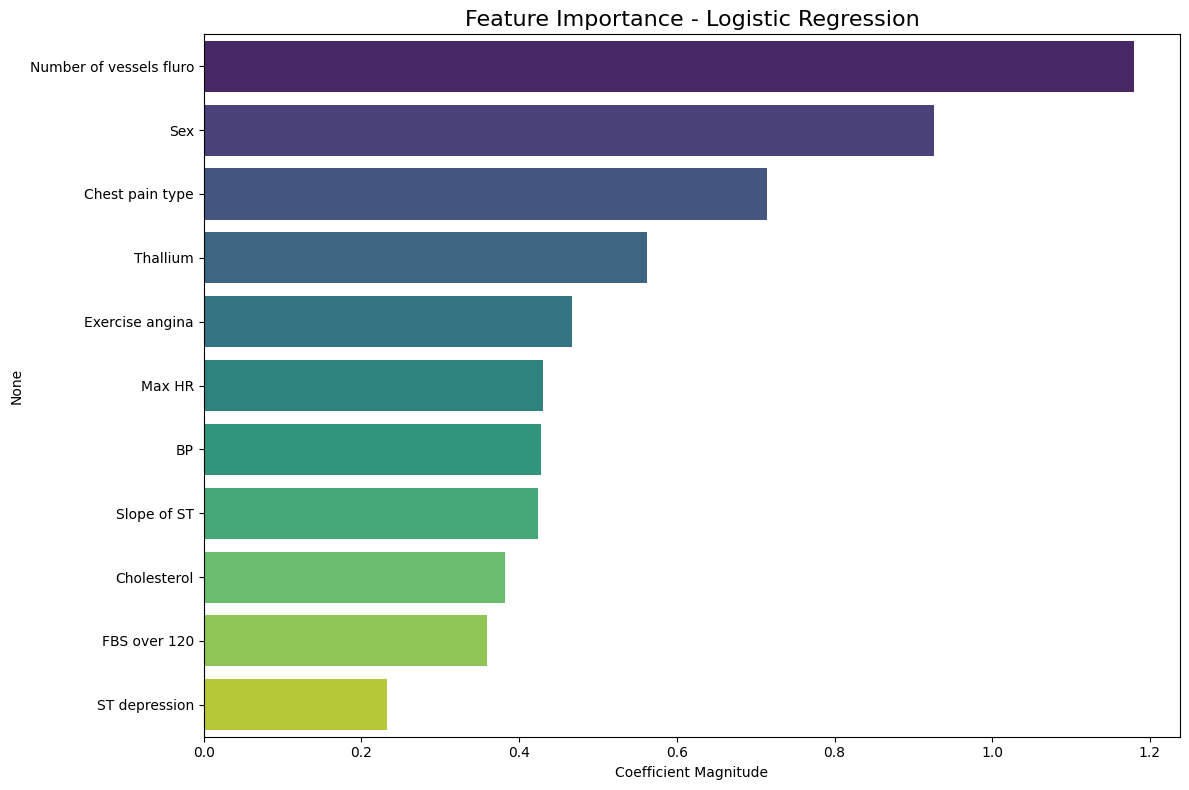

Saved: feature_importance.png

All visuals saved to the 'visuals' folder!
Number of vessels fluro    1.179247
Sex                        0.926083
Chest pain type            0.714291
Thallium                   0.562756
Exercise angina            0.466901
Max HR                     0.429836
BP                         0.428136
Slope of ST                0.423414
Cholesterol                0.382644
FBS over 120               0.359343
ST depression              0.231863
dtype: float64


In [41]:
# ── Feature Importance Chart (just to visualise) ──────────────
importances = pd.Series(np.abs(model_LR.coef_[0]), index=features)
importances = importances.sort_values(ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(x=importances.values, y=importances.index, palette='viridis')
plt.title('Feature Importance - Logistic Regression', fontsize=16)
plt.xlabel('Coefficient Magnitude')
plt.tight_layout()

plt.savefig('visuals/feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: feature_importance.png")

print("\nAll visuals saved to the 'visuals' folder!")

print(importances)

In [37]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# WITH chest pain type — your current features list
X_with = New_hd[features]

# WITHOUT chest pain type — drop it explicitly
X_without = New_hd[[f for f in features if f != 'Chest pain type']]

y = New_hd[output]

# Run cross validation on both
scores_with = cross_val_score(
    LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    X_with, y,
    cv=cv, scoring='f1_macro'
)

scores_without = cross_val_score(
    LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    X_without, y,
    cv=cv, scoring='f1_macro'
)

print(f"WITH    chest pain: {scores_with.mean():.3f} ± {scores_with.std():.3f}")
print(f"WITHOUT chest pain: {scores_without.mean():.3f} ± {scores_without.std():.3f}")

c:\Users\akeem\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\akeem\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\akeem\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\akeem\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:1406: DataC

WITH    chest pain: 0.819 ± 0.049
WITHOUT chest pain: 0.809 ± 0.055


In [38]:
# Save the model and scaler
joblib.dump(model_LR, 'heart_disease_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

print("Model saved successfully!")

Model saved successfully!
